In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.distributional_pca import DistributionalPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))

    min_weights = weights.min()
    max_weights = weights.max()
    diff = max_weights - min_weights
    
    if diff == 0:
        alpha = weights
    else:
        alpha = 0.05 + 0.95 * (weights - min_weights) / diff

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    pc = ts[:,None] * eig_distr_pca[0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="Distributional PCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]

        if k == 0:
            plt.plot(pc[:,0], pc[:,1], c="orange", label="Lifted PCA", alpha=alpha[k])
        else:
            plt.plot(pc[:,0], pc[:,1], c="orange", alpha=alpha[k])

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

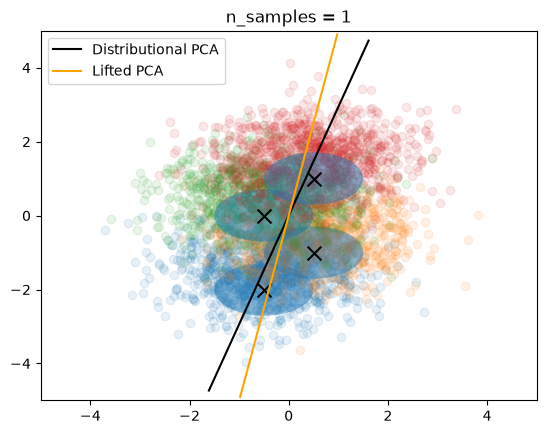

n=1 Lifted 1.1333771347999573 Distributional 1.1210300624370575


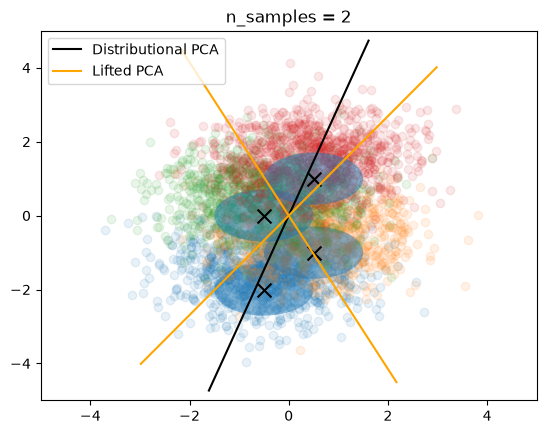

n=2 Lifted 0.5173083394765854 Distributional 1.1210300624370575


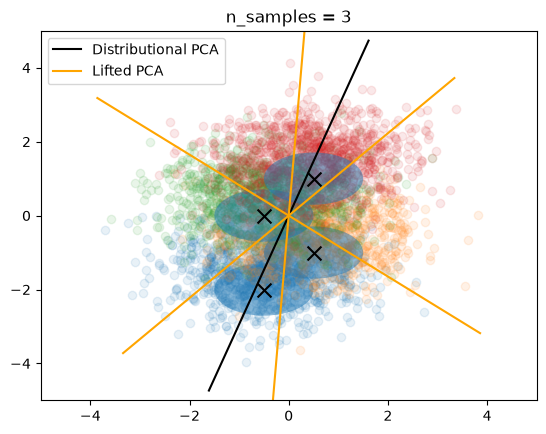

n=3 Lifted 0.3045800179243088 Distributional 1.1210300624370575


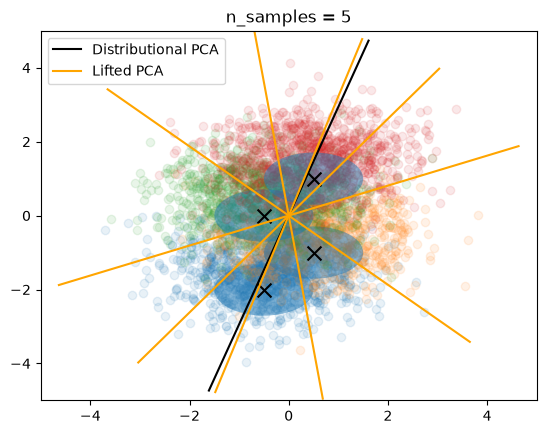

n=5 Lifted 0.16095854341983795 Distributional 1.1210300624370575


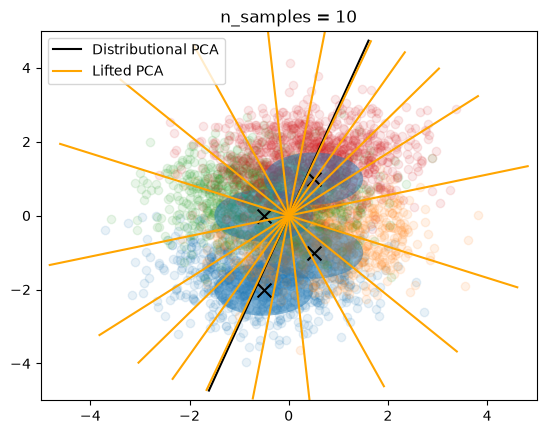

n=10 Lifted 0.08801361732184887 Distributional 1.1210300624370575


In [4]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

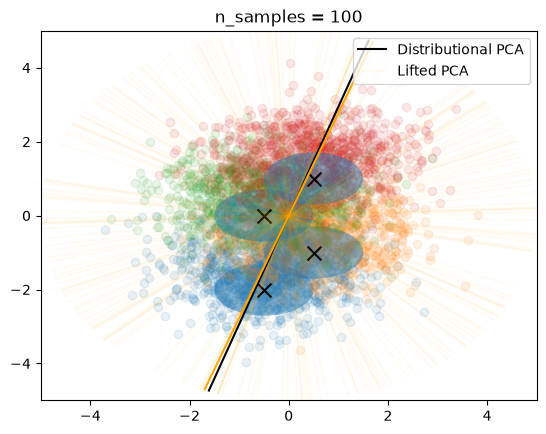

Barycenter cost: 1.0760537534952164


In [5]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

In [6]:
lifted_pca.weights_

tensor([2.6349e-06, 1.1129e-06, 7.2700e-07, 2.3152e-05, 9.9777e-07, 8.1545e-03,
        2.5985e-06, 2.9317e-07, 1.8184e-07, 2.5760e-07, 4.8557e-07, 6.0710e-04,
        7.4187e-06, 8.9500e-04, 1.6972e-07, 2.0652e-06, 1.4510e-06, 5.6990e-06,
        4.3846e-07, 1.2747e-06, 1.9697e-07, 1.8144e-06, 6.2711e-07, 5.9019e-07,
        2.1178e-06, 1.2152e-04, 1.1977e-06, 4.6413e-06, 1.9903e-07, 7.5229e-06,
        1.0608e-05, 3.6245e-07, 1.2506e-06, 3.5349e-07, 1.8494e-07, 3.8176e-07,
        1.7204e-06, 9.3425e-05, 3.4062e-07, 4.8902e-07, 1.2817e-05, 6.8487e-07,
        6.3837e-06, 2.2407e-07, 1.9852e-07, 1.8590e-07, 8.0665e-07, 5.2660e-07,
        1.6836e-07, 2.2048e-07, 4.7642e-06, 1.6799e-07, 2.6672e-06, 6.9574e-07,
        4.3098e-04, 1.8261e-05, 2.3522e-07, 2.3266e-07, 2.6518e-07, 4.5137e-07,
        1.0641e-05, 1.9491e-04, 4.4356e-07, 1.1486e-06, 9.5262e-07, 2.8054e-06,
        8.2093e-06, 4.1794e-06, 2.1273e-07, 1.7702e-07, 1.4626e-06, 2.7135e-07,
        2.9095e-07, 4.4792e-06, 2.2860e-

In [7]:
lifted_pca.weights_.max()

tensor(0.7759)

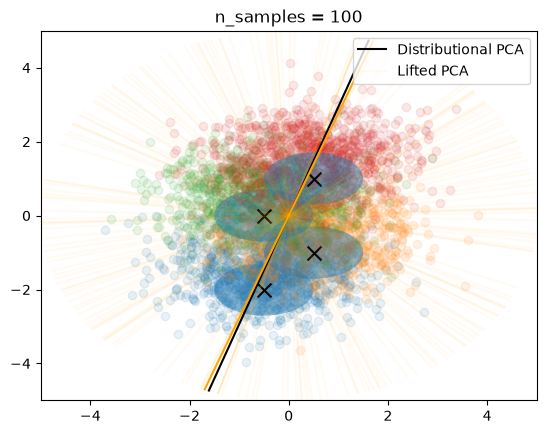

Barycenter cost: 1.0756777673959732


In [8]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20, mode="proximal")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

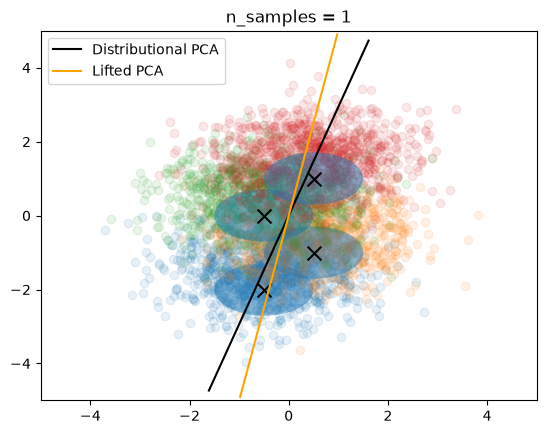

n=1 Lifted 1.1333771347999573 Distributional 1.1210300624370575
[1.]


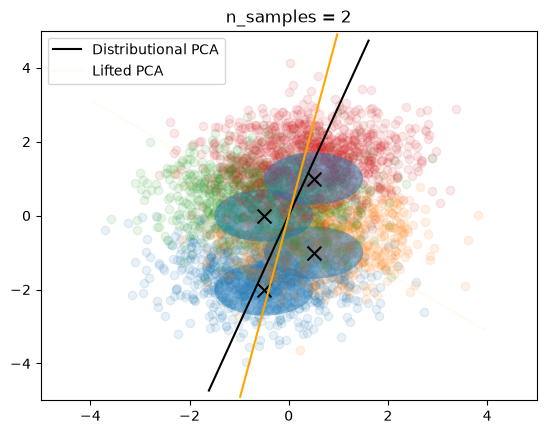

n=2 Lifted 1.1333769410848618 Distributional 1.1210300624370575
[1.4288472e-08 1.0000000e+00]


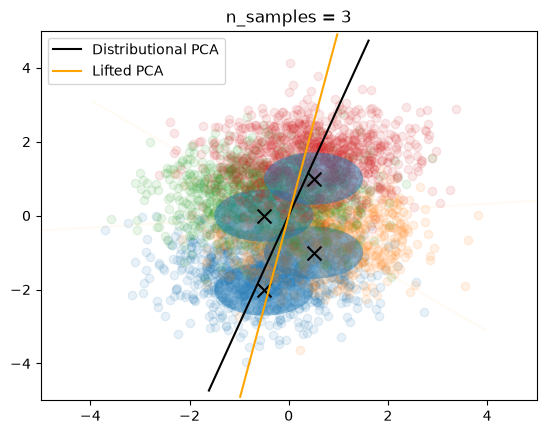

n=3 Lifted 1.1333769112825394 Distributional 1.1210300624370575
[1.0000000e+00 1.1902903e-09 2.9390804e-08]


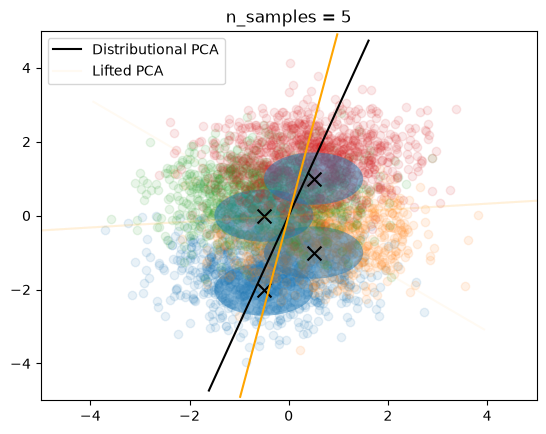

n=5 Lifted 1.1333767771720886 Distributional 1.1210300624370575
[8.0492037e-14 2.1106302e-08 1.0933347e-14 7.7977738e-14 1.0000000e+00]


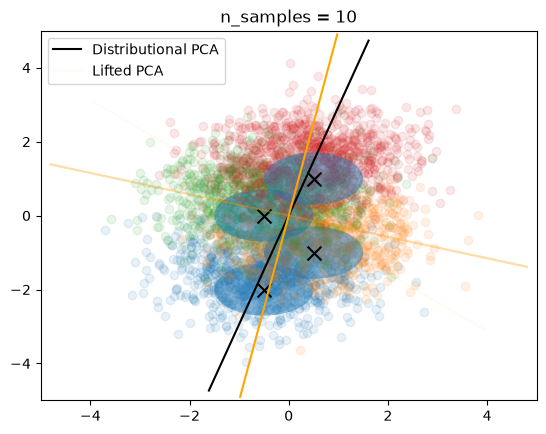

n=10 Lifted 1.1333766728639603 Distributional 1.1210300624370575
[5.9919434e-16 8.1408567e-14 1.9201873e-15 2.7746847e-15 1.0610209e-13
 8.2694556e-15 7.9368988e-16 1.0000000e+00 1.4267486e-14 2.6821258e-08]


In [9]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [10]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

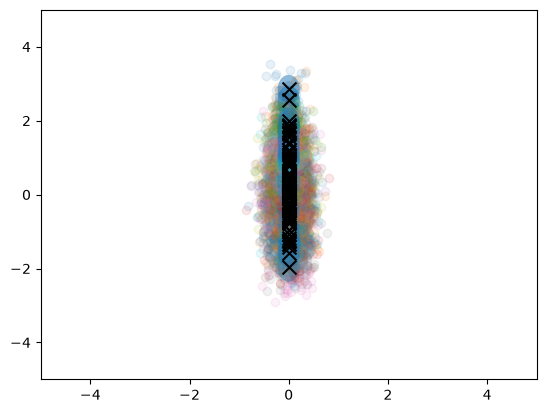

In [11]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

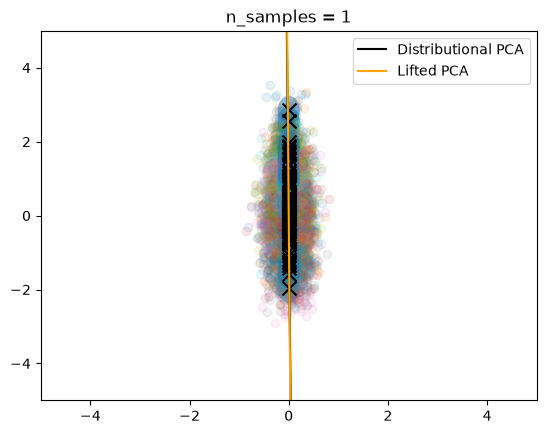

n=1 Lifted 0.05051559628918767 Distributional 0.05051364794373512


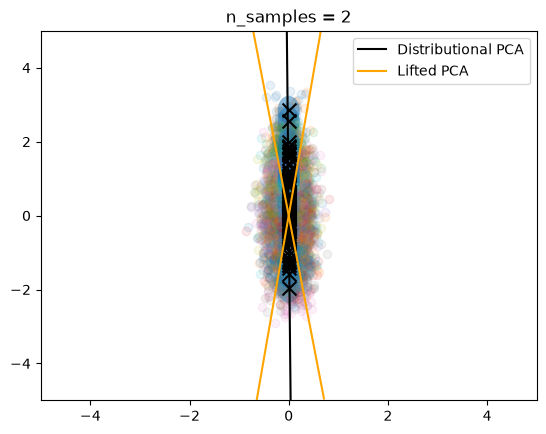

n=2 Lifted 0.030163431838154793 Distributional 0.05051364794373512


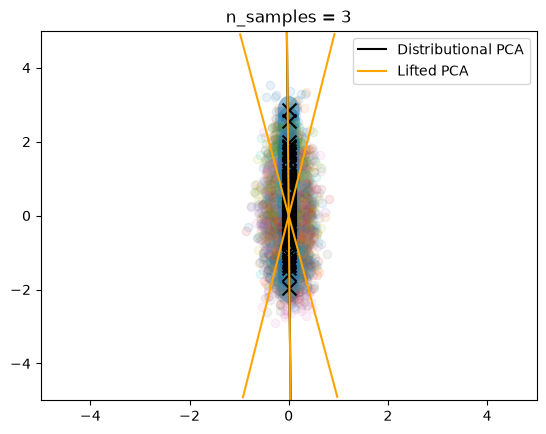

n=3 Lifted 0.024382332898676397 Distributional 0.05051364794373512


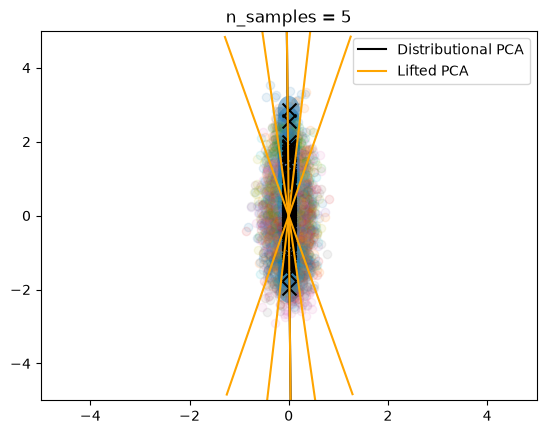

n=5 Lifted 0.02020111246500164 Distributional 0.05051364794373512


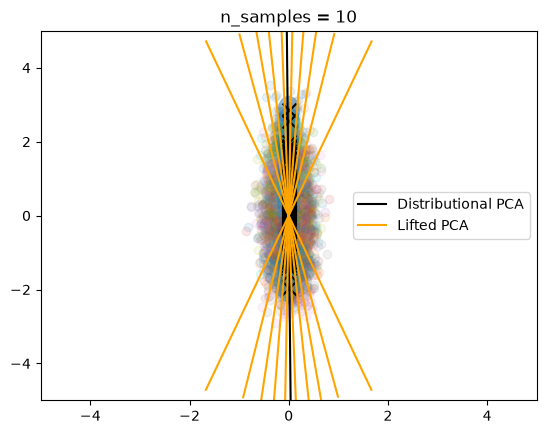

n=10 Lifted 0.017461701813153922 Distributional 0.05051364794373512


In [12]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

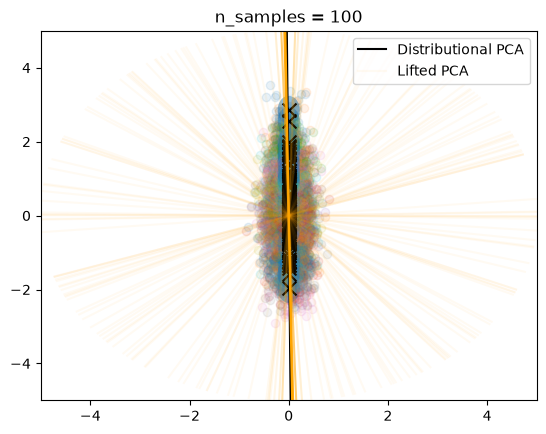

0.04172307909466326


In [13]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support")
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [14]:
lifted_pca.weights_

tensor([3.4273e-04, 3.7910e-05, 2.5437e-06, 4.1880e-06, 4.6387e-04, 2.5362e-06,
        1.6575e-06, 5.9415e-06, 6.9997e-03, 5.1746e-06, 9.4086e-06, 1.7314e-06,
        9.6783e-04, 8.6031e-04, 1.6577e-06, 1.4525e-05, 4.0006e-06, 2.6030e-06,
        5.7737e-03, 1.5274e-04, 5.3339e-05, 1.3504e-02, 7.6344e-05, 1.0773e-05,
        2.2803e-04, 2.4602e-05, 4.2939e-03, 6.8736e-06, 2.5603e-04, 3.1871e-01,
        8.6245e-06, 2.5313e-06, 2.9828e-05, 2.1179e-06, 3.2091e-06, 2.1274e-05,
        1.7134e-03, 3.7572e-05, 2.1700e-06, 5.0484e-06, 5.7794e-06, 1.6859e-06,
        6.9840e-03, 4.0936e-04, 2.6997e-06, 1.1325e-05, 2.4654e-06, 1.6591e-06,
        4.1265e-02, 3.6437e-06, 8.5543e-02, 2.3299e-06, 3.3687e-06, 1.6578e-06,
        5.5440e-06, 1.7414e-01, 1.0033e-04, 1.7731e-06, 1.0452e-05, 4.2688e-06,
        1.6575e-06, 1.0811e-05, 8.5960e-06, 4.9162e-05, 1.6826e-06, 1.6556e-05,
        2.5117e-04, 2.0753e-06, 2.3083e-06, 5.6408e-06, 2.0583e-05, 1.0107e-05,
        2.2008e-06, 1.1503e-05, 6.8653e-

In [15]:
lifted_pca.weights_.max()

tensor(0.3187)

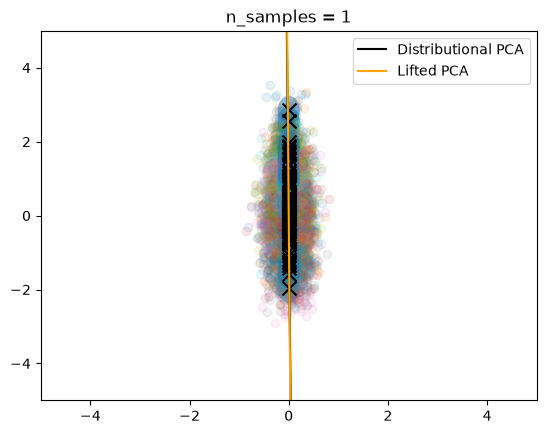

n=1 Lifted 0.05051559628918767 Distributional 0.05051364794373512
[1.]


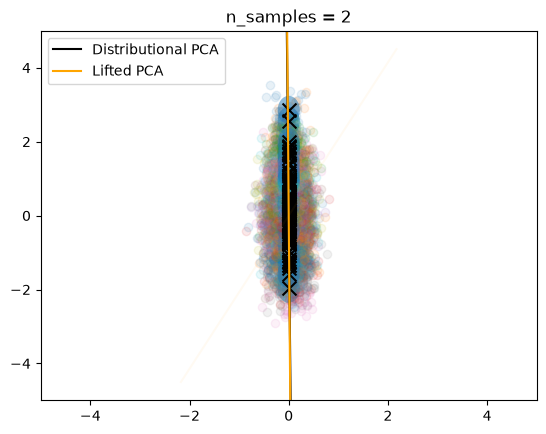

n=2 Lifted 0.0505155917070806 Distributional 0.05051364794373512
[1.000000e+00 3.371082e-08]


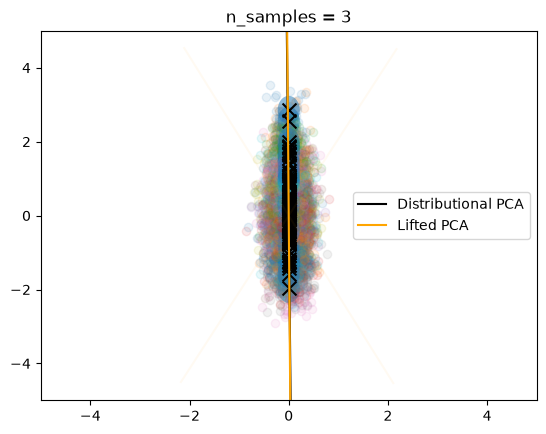

n=3 Lifted 0.050515594128519296 Distributional 0.05051364794373512
[1.0000000e+00 1.1624554e-08 5.9086545e-09]


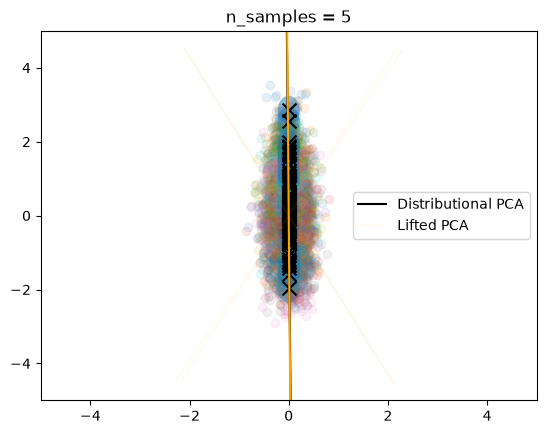

n=5 Lifted 0.05051534563302994 Distributional 0.05051364794373512
[2.2794308e-10 4.8814286e-09 1.0000000e+00 7.3772453e-11 6.3443686e-09]


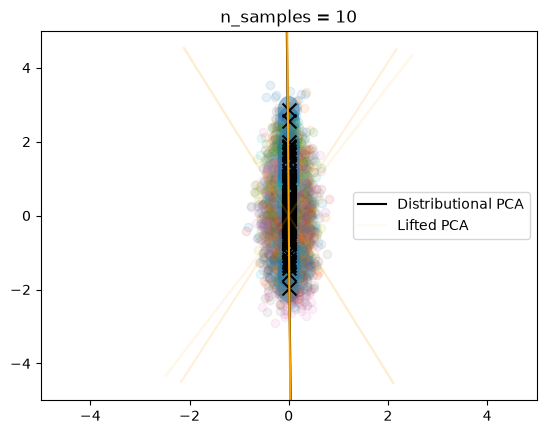

n=10 Lifted 0.05051532862707973 Distributional 0.05051364794373512
[8.2158775e-17 4.2538106e-18 9.9999988e-01 1.8241617e-15 1.0855765e-17
 1.6799511e-16 2.4673742e-17 1.3252776e-15 4.7381379e-17 9.2850073e-08]


In [16]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [17]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

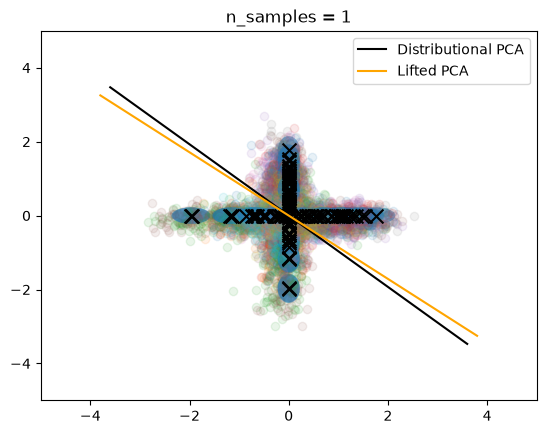

n=1 Lifted 0.4863806875050068 Distributional 0.48630269601941106


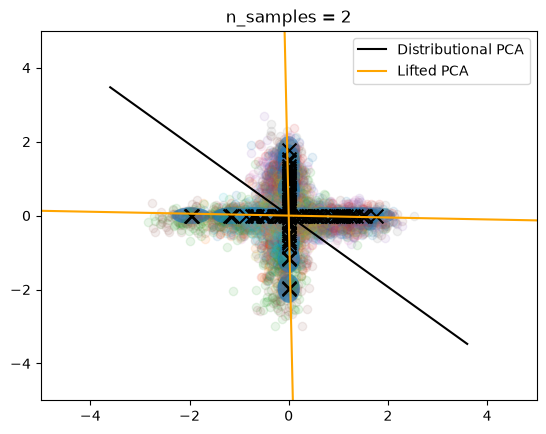

n=2 Lifted 0.26495240177959206 Distributional 0.48630269601941106


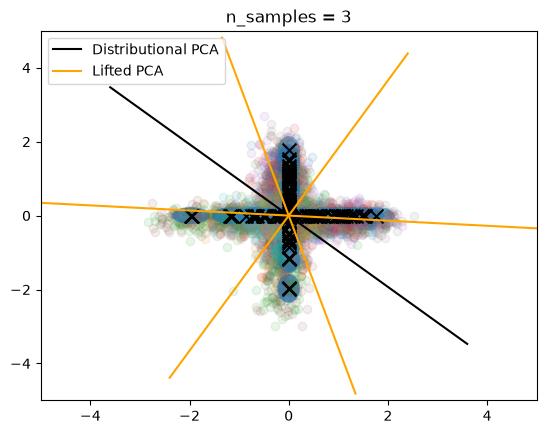

n=3 Lifted 0.2474915242008865 Distributional 0.48630269601941106


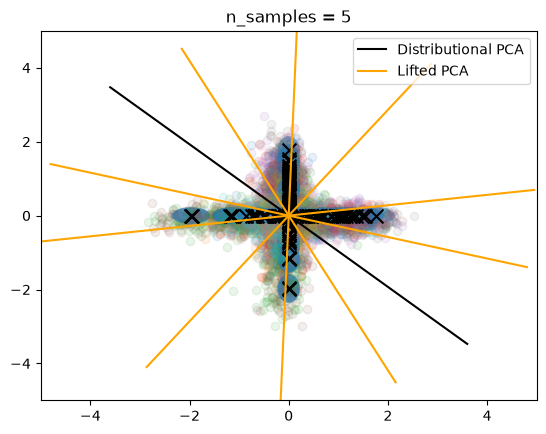

n=5 Lifted 0.2192468182044104 Distributional 0.48630269601941106


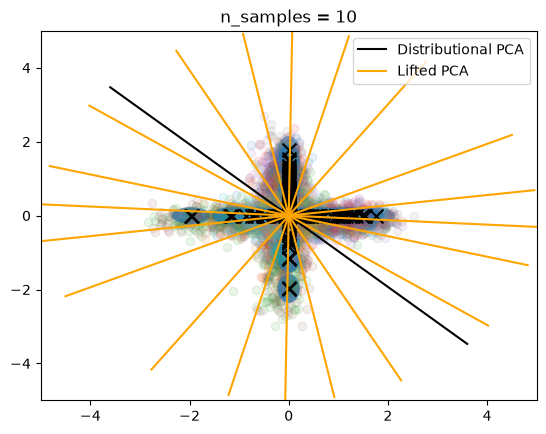

n=10 Lifted 0.20589611963136123 Distributional 0.48630269601941106


In [23]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

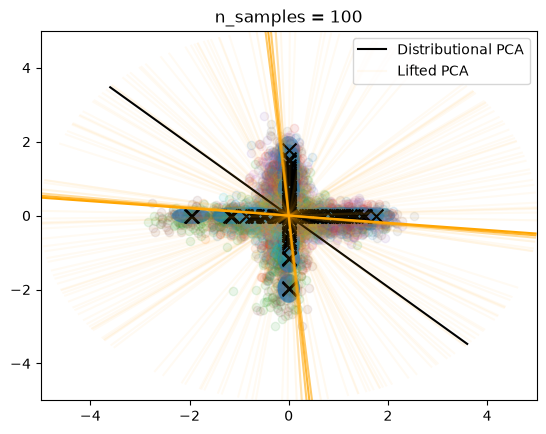

0.2616030519641936


In [30]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [28]:
lifted_pca.weights_

tensor([5.0388e-05, 3.5065e-05, 1.2210e-03, 5.6965e-05, 1.4714e-03, 2.4727e-05,
        5.2827e-05, 4.0765e-04, 9.8544e-03, 5.9036e-05, 1.1164e-04, 6.3171e-06,
        6.4644e-06, 6.8729e-06, 1.5067e-03, 1.0499e-05, 2.2694e-05, 8.2534e-02,
        4.7376e-05, 3.3143e-05, 6.5910e-06, 9.4883e-06, 1.9515e-01, 9.8310e-05,
        2.3508e-05, 9.7063e-06, 1.3344e-05, 1.3598e-03, 1.2964e-05, 6.5117e-06,
        3.9931e-05, 7.9451e-06, 9.4187e-06, 6.4252e-06, 2.0843e-04, 1.4877e-03,
        1.8134e-03, 6.4607e-06, 1.5699e-03, 2.1616e-04, 7.5383e-06, 7.3089e-05,
        5.4307e-05, 6.4669e-06, 2.9921e-01, 7.1285e-06, 2.4137e-05, 1.7237e-05,
        8.9788e-05, 2.9738e-05, 2.6521e-04, 5.6295e-05, 2.4673e-05, 1.8627e-04,
        4.8909e-03, 1.8740e-05, 1.3203e-04, 1.1822e-05, 1.1388e-04, 6.6336e-06,
        2.5180e-05, 5.3452e-05, 8.8058e-05, 6.5517e-06, 2.3809e-04, 2.3423e-05,
        1.2370e-05, 6.5461e-06, 2.3126e-05, 5.1625e-05, 1.8422e-04, 1.6372e-04,
        4.4611e-05, 6.3269e-06, 2.3448e-

In [29]:
lifted_pca.weights_.max()

tensor(0.3892)

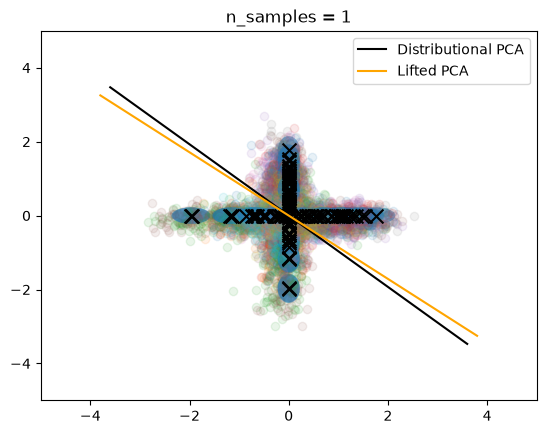

n=1 Lifted 0.4863806875050068 Distributional 0.48630269601941106
[1.]


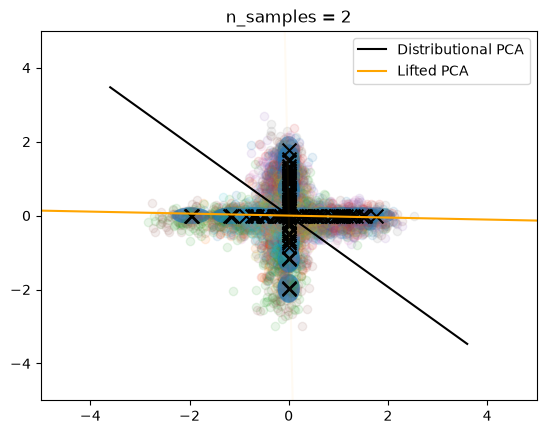

n=2 Lifted 0.2650432617217302 Distributional 0.48630269601941106
[0.50401455 0.49598548]


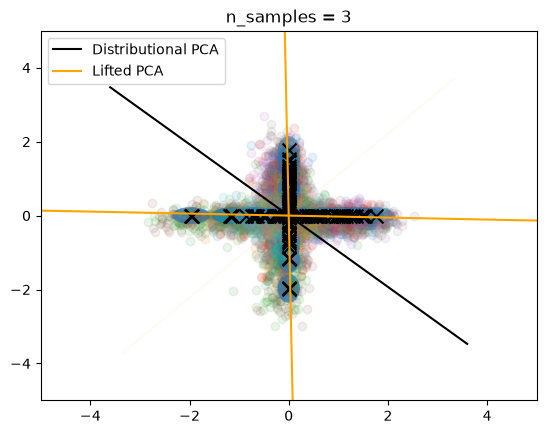

n=3 Lifted 0.26504378419369456 Distributional 0.48630269601941106
[4.9590266e-01 4.1619069e-06 5.0409311e-01]


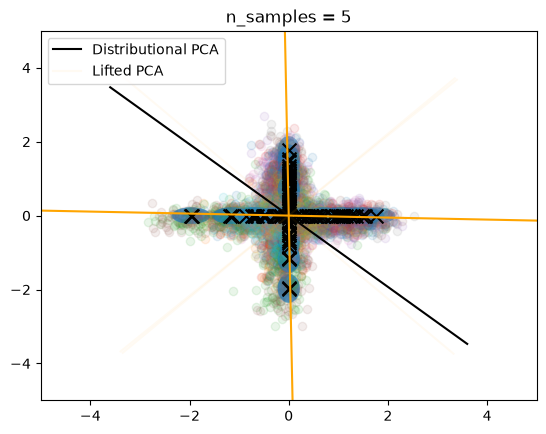

n=5 Lifted 0.26502136323601005 Distributional 0.48630269601941106
[7.7473146e-07 7.3965246e-05 1.0829298e-05 4.9577537e-01 5.0413907e-01]


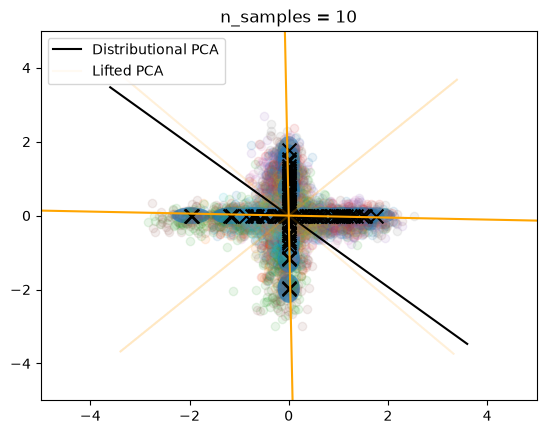

n=10 Lifted 0.2650326591916382 Distributional 0.48630269601941106
[8.1303675e-08 4.2930438e-08 1.8544069e-06 3.4355053e-05 4.9584004e-01
 2.5661043e-06 5.8320711e-06 5.0411516e-01 1.0996421e-08 8.1903195e-09]


In [22]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())